In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Se pide, usando regresión lineal:

Dibujar con una línea la relación que hay entre la altura y la edad de los alumnos de esta clase: 

In [2]:
lista_alumnos = [("Leonardo S", 24, 1.82), 
                 ("Piero T", 25, 1.71), 
                 ("Marta B", 35, 1.66), 
                 ("Silvia P", 37, 1.63), 
                 ("Faro Z", 29, 1.90), 
                 ("Miguel N", 27, 1.80), 
                 ("Alejandro M", 28, 1.70), 
                 ("Cristina M", 32, 1.60), 
                 ("Francisco P", 36, 1.74), 
                 ("Jorge D", 45, 1.72), 
                 ("Jesús L", 41, 1.65), 
                 ("Marta G", 30, 1.65), 
                 ("Jennifer S", 40, 1.60), 
                 ("Diego I", 39, 1.80), 
                 ("Antonio C", 23, 1.77), 
                 ("Juan M", 32, 1.75), 
                 ("David S", 27, 1.70), 
                 ("Antonio J", 34, 1.80), 
                 ("Carlos H", 27, 1.77), 
                 ("Erik U", 28, 1.70), 
                 ("Marcos L", 35, 1.80)] 

In [3]:
# Crear el DataFrame
df = pd.DataFrame(lista_alumnos, columns=["Nombre", "Edad", "Altura"])

            Edad     Altura
count  21.000000  21.000000
mean   32.095238   1.727143
std     6.081980   0.079003
min    23.000000   1.600000
25%    27.000000   1.660000
50%    32.000000   1.720000
75%    36.000000   1.800000
max    45.000000   1.900000
            Edad    Altura
Edad    1.000000 -0.329275
Altura -0.329275  1.000000


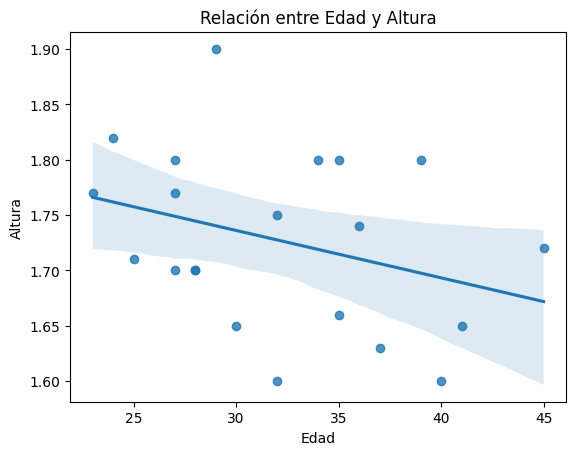

In [4]:
# Análisis descriptivo estadístico
print(df.describe())

# Matriz de correlación para ver la relación numérica
print(df.corr(numeric_only=True))

# Visualización de la relación con una línea de regresión
sns.regplot(x='Edad', y='Altura', data=df)
plt.title('Relación entre Edad y Altura')
plt.show()

### ¿Es una buena técnica para este tipo de problemas? Demuéstralo antes de entrenar un modelo con un análisis descriptivo.

In [ ]:
#No es una buena técnica

### Entrena un modelo de regresión lineal

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [6]:
# Separar X (features) e y (target)
X = df[['Edad']] 
y = df['Altura']

# Dividir los datos (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Entrenar el modelo
lm = LinearRegression()
lm.fit(X_train, y_train)

# Realizar predicciones
predicciones = lm.predict(X_test)

### ¿Qué error se comete? Calcula los errores que está cometiendo tu modelo de forma manual con python. Aparte, usa las métricas de sklearn MAE, MAPE, MSE y el RMSE.

In [ ]:
from sklearn import metrics

# 1. Errores usando sklearn 
print('MAE:', metrics.mean_absolute_error(y_test, predicciones))
print('MSE:', metrics.mean_squared_error(y_test, predicciones))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predicciones)))
print('MAPE:', metrics.mean_absolute_percentage_error(y_test, predicciones))

# 2. Cálculo de los errores de forma manual con Python
errores = y_test - predicciones

mae_manual = np.mean(np.abs(errores))
mse_manual = np.mean(errores**2)
rmse_manual = np.sqrt(mse_manual)
mape_manual = np.mean(np.abs(errores / y_test))

print("\nCálculo manual:")
print('MAE manual:', mae_manual)
print('MSE manual:', mse_manual)
print('RMSE manual:', rmse_manual)
print('MAPE manual:', mape_manual)

MAE: 0.05706488156539665
MSE: 0.0036851216240520687
RMSE: 0.060705202611078306
MAPE: 0.03253724207144201

Cálculo manual:
MAE manual: 0.05706488156539665
MSE manual: 0.0036851216240520687
RMSE manual: 0.060705202611078306
MAPE manual: 0.03253724207144201
